# Ola Ride Insights: Exploratory Data Analysis (EDA)

**Project:** Ola Ride Insights, ride sharing and mobility analytics
**Data:** One month of Ola bookings (July 2024), 103,024 rows

| Link | Address |
|---|---|
| GitHub repository | https://github.com/YOUR_USERNAME/ola-ride-insights |
| Live Streamlit dashboard | https://YOUR_APP_NAME.streamlit.app |

### About this notebook
This notebook contains the exploratory data analysis of the Ola ride data. In each section I explain what I am doing, show the code, and then write my observation.

### Questions I want to answer
1. How many bookings become completed rides, and how much booking value is lost when they do not?
2. Why are rides cancelled and who is responsible?
3. At what time do people book, and is there a peak time?
4. Which vehicle types and payment methods matter most?
5. Can the data be trusted, for example does price depend on distance?

## 1. Setup and load the data
I load the cleaned file created by `src/cleaning.py` and add a few helper columns (hour, weekday, success flag and so on) from `src/features.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Find the project folder so the notebook runs from anywhere
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_loader import load_data

# Simple chart style
PALETTE = ["#A3B800", "#0F766E", "#2563EB", "#7C3AED", "#D97706", "#DC2626", "#64748B"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

df = load_data()
ok = df[df["Is_Success"]]
print("Rows and columns:", df.shape)

Rows and columns: (103024, 34)

## 2. Understand the dataset
**What I do:** Check the size, the columns and the data types of the dataset.

In [2]:
# First five rows
df[["Booking_Datetime", "Booking_ID", "Booking_Status", "Vehicle_Type", "Pickup_Location",
    "Drop_Location", "Booking_Value", "Payment_Method", "Ride_Distance", "Driver_Ratings"]].head()

,Booking_Datetime,Booking_ID,Booking_Status,Vehicle_Type,Pickup_Location,Drop_Location,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings
0,2024-07-01 00:00:00,CNR4197668379,Success,Prime Plus,Malleshwaram,BTM Layout,791,Cash,31,3.10
1,2024-07-01 00:00:00,CNR4091573505,Canceled by Driver,eBike,Yeshwanthpur,Devanahalli,367,NaN,0,NaN
2,2024-07-01 00:02:00,CNR7037451850,Canceled by Driver,Mini,Padmanabhanagar,Magadi Road,1985,NaN,0,NaN
3,2024-07-01 00:03:00,CNR3610392570,Success,eBike,JP Nagar,Sarjapur Road,120,Credit Card,26,3.10
4,2024-07-01 00:04:00,CNR8282131599,Success,Auto,Langford Town,JP Nagar,170,Cash,5,4.30


In [3]:
# Column names and data types
info = pd.DataFrame({"Type": df.dtypes.astype(str), "Unique values": df.nunique(), "Blank cells": df.isna().sum()})
info.loc[["Booking_Datetime", "Booking_Status", "Customer_ID", "Vehicle_Type", "Pickup_Location",
          "V_TAT", "Booking_Value", "Payment_Method", "Ride_Distance", "Driver_Ratings"]]

,Type,Unique values,Blank cells
Booking_Datetime,datetime64[us],40214,0
Booking_Status,str,4,0
Customer_ID,str,94544,0
Vehicle_Type,str,7,0
Pickup_Location,str,50,0
V_TAT,float64,40,39057
Booking_Value,int64,2883,0
Payment_Method,str,4,39057
Ride_Distance,int64,50,0
Driver_Ratings,float64,21,39057


**Observation**
- 103,024 bookings, 94,544 different customers, 7 vehicle types, 50 pickup areas, from 1 July to 31 July 2024.
- Every row is one booking. It can end in four ways: Success, Canceled by Customer, Canceled by Driver or Driver Not Found.
- `V_TAT` and `C_TAT` are turnaround times. The file does not give the unit. They look like seconds, so please confirm with the data owner.

## 3. Data quality: blanks and duplicates
**What I do:** Count the blank cells and repeated bookings.
**Why:** Wrong or missing data gives wrong results.

In [4]:
# Duplicates and blank cells
print("Duplicate booking ids:", df["Booking_ID"].duplicated().sum())
blank = df.isna().sum()
blank = blank[blank > 0].to_frame("Blank cells")
blank["Share of rows"] = blank["Blank cells"] / len(df) * 100
blank

Duplicate booking ids: 0

,Blank cells,Share of rows
V_TAT,39057,37.91
C_TAT,39057,37.91
Canceled_Rides_by_Customer,92525,89.81
Canceled_Rides_by_Driver,84590,82.11
Incomplete_Rides,39057,37.91
Incomplete_Rides_Reason,99098,96.19
Payment_Method,39057,37.91
Driver_Ratings,39057,37.91
Customer_Rating,39057,37.91
Failure_Owner,63967,62.09


**Observation**
- There are no duplicate bookings.
- Blank cells are not errors. They depend on how the booking ended: a cancelled ride never gets a payment method, a rating, a distance or a turnaround time. A ride that was not incomplete has no incomplete reason.
- So I do not fill these blanks with averages. Filling them would create data that never existed.

In [5]:
# Check that the blanks follow the business rules
failed = df[~df["Is_Success"]]
print("Failed bookings with a payment method:", failed["Payment_Method"].notna().sum())
print("Failed bookings with a rating:", failed["Driver_Ratings"].notna().sum())
print("Failed bookings with distance above zero:", (failed["Ride_Distance"] > 0).sum())
print("Completed rides with no payment method:", ok["Payment_Method"].isna().sum())
print("Completed rides with distance zero:", (ok["Ride_Distance"] == 0).sum())

Failed bookings with a payment method: 0
Failed bookings with a rating: 0
Failed bookings with distance above zero: 0
Completed rides with no payment method: 0
Completed rides with distance zero: 0

**Observation:** All checks show zero. The data follows its own rules. One important point: failed bookings have distance 0, so any average distance must use completed rides only, otherwise the average is pulled down from about 22.9 km to about 14.2 km.

In [6]:
# Wrong way and right way to calculate average distance
print("Average distance, all bookings (wrong):", round(df["Ride_Distance"].mean(), 2))
print("Average distance, completed rides (right):", round(ok["Ride_Distance"].mean(), 2))

Average distance, all bookings (wrong): 14.19
Average distance, completed rides (right): 22.85

## 4. Summary statistics
**What I do:** Find the average, spread, smallest value and largest value of each number column.

In [7]:
# Numbers for completed rides
ok[["Booking_Value", "Ride_Distance", "V_TAT", "C_TAT", "Driver_Ratings", "Customer_Rating"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Booking_Value,"63,967.00",548.42,536.65,100.00,242.00,385.00,622.00,"2,999.00"
Ride_Distance,"63,967.00",22.85,14.24,1.00,10.00,21.00,35.00,49.00
V_TAT,"63,967.00",170.88,80.80,35.00,98.00,168.00,238.00,308.00
C_TAT,"63,967.00",84.87,36.01,25.00,55.00,85.00,115.00,145.00
Driver_Ratings,"63,967.00",4.00,0.58,3.00,3.50,4.00,4.50,5.00
Customer_Rating,"63,967.00",4.00,0.58,3.00,3.50,4.00,4.50,5.00


**Observation**
- Booking value runs from Rs 100 to Rs 2,999 with an average near Rs 548 and a middle value (median) of Rs 385.
- Ride distance runs from 1 to 49 km, average 22.9 km.
- Both ratings sit between 3.0 and 5.0 with an average of 4.0. Nobody gave a rating below 3.0, which is unusual for real riders.

In [8]:
# How are bookings split by status
status = df["Booking_Status"].value_counts().to_frame("Bookings")
status["Share %"] = status["Bookings"] / len(df) * 100
status

,Bookings,Share %
Booking_Status,,
Success,63967,62.09
Canceled by Driver,18434,17.89
Canceled by Customer,10499,10.19
Driver Not Found,10124,9.83


**Observation:** Only 62.1% of bookings become rides. The remaining 37.9% fail. This is the main finding of the project, and the next sections look at the reasons.

## 5. One column at a time (univariate analysis)

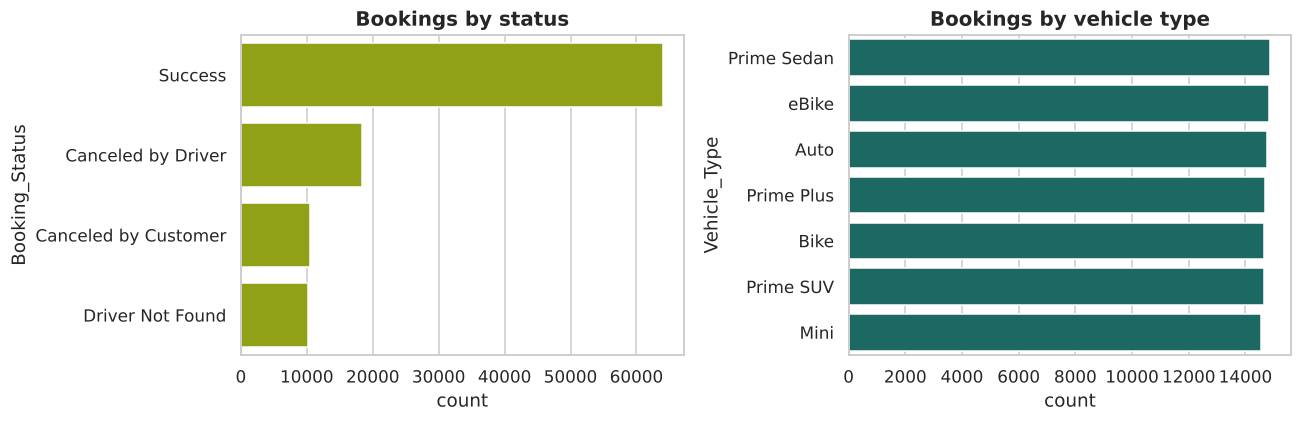

In [9]:
# Bookings by status and vehicle type
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = df["Booking_Status"].value_counts().index
sns.countplot(data=df, y="Booking_Status", order=order, ax=ax[0], color="#A3B800")
ax[0].set_title("Bookings by status")
sns.countplot(data=df, y="Vehicle_Type", order=df["Vehicle_Type"].value_counts().index, ax=ax[1], color="#0F766E")
ax[1].set_title("Bookings by vehicle type")
plt.tight_layout()

**Observation:** The seven vehicle types have almost equal booking numbers (about 14,500 to 15,000 each). No vehicle type dominates the demand.

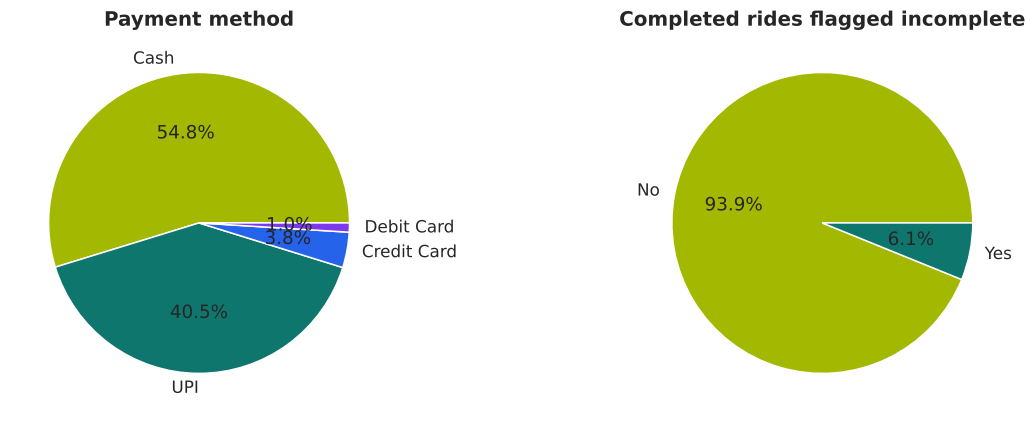

In [10]:
# Payment method and incomplete rides, completed rides only
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ok["Payment_Method"].value_counts().plot.pie(autopct="%.1f%%", ax=ax[0], colors=PALETTE, ylabel="")
ax[0].set_title("Payment method")
ok["Incomplete_Rides"].value_counts().plot.pie(autopct="%.1f%%", ax=ax[1], colors=PALETTE, ylabel="")
ax[1].set_title("Completed rides flagged incomplete")
plt.tight_layout()

**Observation**
- Cash 54.8% of rides, UPI 40.5%, cards only about 4.8%. More than half of the business still handles cash.
- 6.1% of completed rides are flagged incomplete. These rides are counted as Success but did not finish fully, so revenue reports can be overstated.

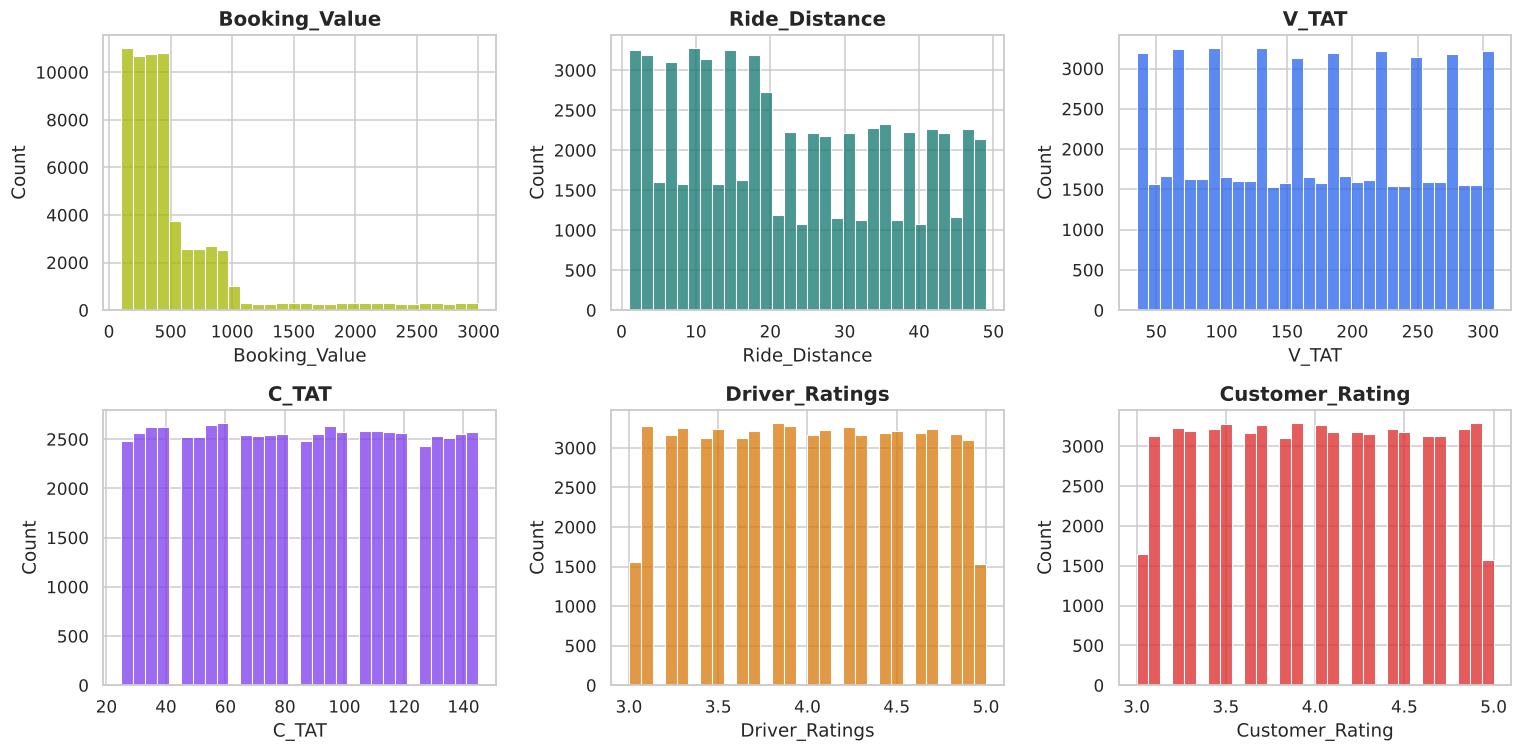

In [11]:
# Shape of the number columns
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, col, color in zip(ax.ravel(), ["Booking_Value", "Ride_Distance", "V_TAT", "C_TAT", "Driver_Ratings", "Customer_Rating"],
                         PALETTE):
    sns.histplot(ok[col], bins=30, ax=a, color=color)
    a.set_title(col)
plt.tight_layout()

In [12]:
# Skewness tells us if a column leans to one side
ok[["Booking_Value", "Ride_Distance", "V_TAT", "C_TAT", "Driver_Ratings", "Customer_Rating"]].skew().to_frame("Skewness")

,Skewness
Booking_Value,2.58
Ride_Distance,0.22
V_TAT,0.01
C_TAT,0.01
Driver_Ratings,0.00
Customer_Rating,0.01


**Observation**
- Booking value leans strongly to the right (skewness 2.6): many cheap rides and a few very expensive ones.
- Distance, both turnaround times and both ratings are almost flat, which means values are spread evenly across their range. Real ride data usually has more variation, so this data may be sample data. I kept this in mind while reading the results.

## 6. Outliers
**What I do:** Use the IQR rule. A value is an outlier if it is far below Q1 or far above Q3.

In [13]:
# IQR outlier count for each number column
rows = []
for col in ["Booking_Value", "Ride_Distance", "V_TAT", "C_TAT"]:
    q1, q3 = ok[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((ok[col] < low) | (ok[col] > high)).sum()
    rows.append([col, low, high, count, count / len(ok) * 100])
pd.DataFrame(rows, columns=["Column", "Lower limit", "Upper limit", "Outliers", "Share %"])

,Column,Lower limit,Upper limit,Outliers,Share %
0,Booking_Value,-328.00,"1,192.00",5198,8.13
1,Ride_Distance,-27.50,72.50,0,0.00
2,V_TAT,-112.00,448.00,0,0.00
3,C_TAT,-35.00,205.00,0,0.00


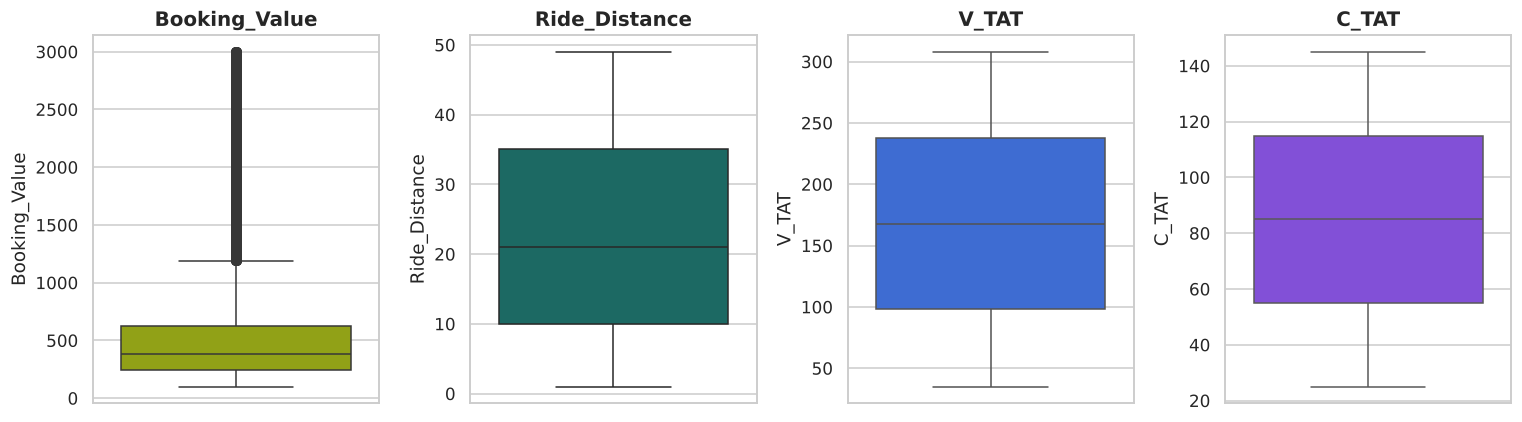

In [14]:
# Box plots
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, col, color in zip(ax, ["Booking_Value", "Ride_Distance", "V_TAT", "C_TAT"], PALETTE):
    sns.boxplot(y=ok[col], ax=a, color=color)
    a.set_title(col)
plt.tight_layout()

**Observation**
- Ride distance and both turnaround times have no outliers.
- Booking value has 5,198 values (8.1%) above the upper limit of Rs 1,192. This is a long right tail of expensive rides, not a data mistake, so I keep them.
- Rule I followed: remove an outlier only when it is a clear mistake. None of these are.

## 7. Two columns together (bivariate analysis)
### 7.1 Numbers against numbers

Text(0.5, 1.0, 'Correlation heatmap')

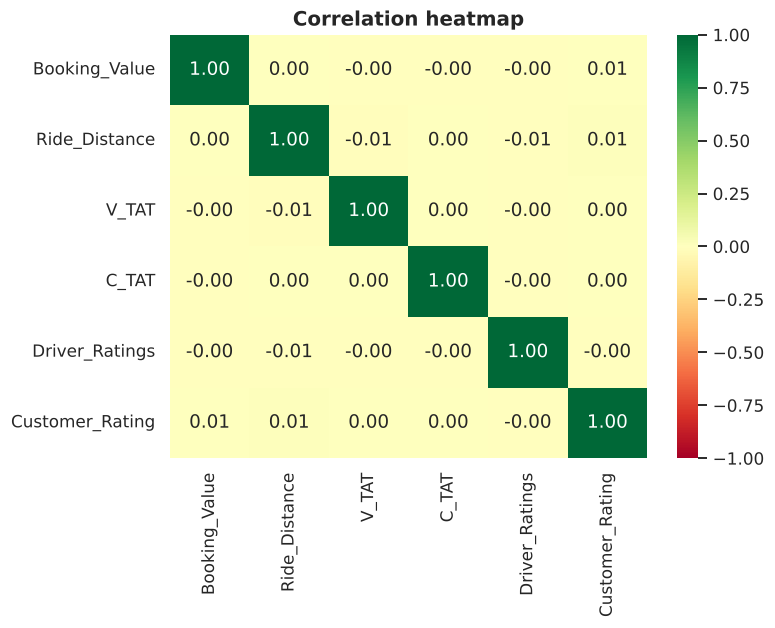

In [15]:
# Correlation of the number columns, completed rides only
cols = ["Booking_Value", "Ride_Distance", "V_TAT", "C_TAT", "Driver_Ratings", "Customer_Rating"]
plt.figure(figsize=(7, 5))
sns.heatmap(ok[cols].corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap")

**Observation:** Every correlation is close to zero. The most important pair is Booking value and Ride distance (0.00). In a real ride business, a longer ride costs more. Here, distance does not explain price at all.

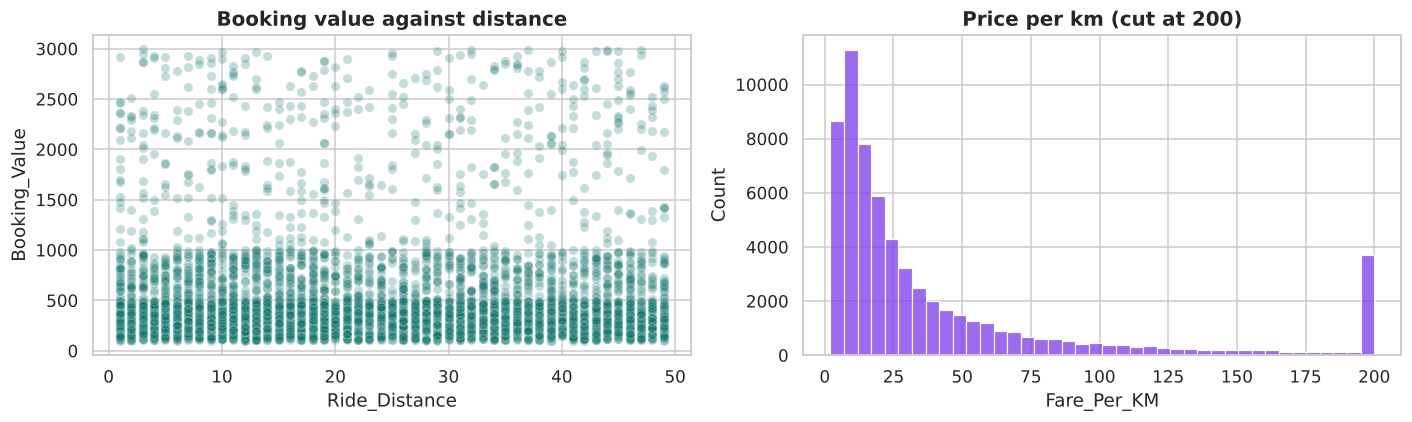

In [16]:
# Price against distance
sample = ok.sample(5000, random_state=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=sample, x="Ride_Distance", y="Booking_Value", alpha=0.25, ax=ax[0], color="#0F766E")
ax[0].set_title("Booking value against distance")
sns.histplot(ok["Fare_Per_KM"].clip(upper=200), bins=40, ax=ax[1], color="#7C3AED")
ax[1].set_title("Price per km (cut at 200)")
plt.tight_layout()

In [17]:
# Price per km summary
print("Median price per km:", round(ok["Fare_Per_KM"].median(), 1))
print("Rides above 10 times the median:", (ok["Fare_Per_KM"] > 10 * ok["Fare_Per_KM"].median()).sum())
print("Rides below a quarter of the median:", (ok["Fare_Per_KM"] < 0.25 * ok["Fare_Per_KM"].median()).sum())

Median price per km: 20.4
Rides above 10 times the median: 3532
Rides below a quarter of the median: 4546

**Observation:** The scatter plot is a flat cloud with no upward slope. The price per km ranges from a few rupees to several hundred. About 3,500 rides cost more than ten times the median price per km and about 4,500 cost less than a quarter of it. This looks like a pricing issue, and it also affects how much the data can be trusted.

### 7.2 Categories against numbers (vehicle type)

In [18]:
# Distance and value for each vehicle type
vehicle = ok.groupby("Vehicle_Type").agg(
    Rides=("Booking_ID", "size"), Avg_Distance=("Ride_Distance", "mean"), Avg_Value=("Booking_Value", "mean"),
    Revenue=("Booking_Value", "sum"), Total_Km=("Ride_Distance", "sum"),
    Driver_Rating=("Driver_Ratings", "mean"), Customer_Rating=("Customer_Rating", "mean"))
vehicle["Revenue_Per_KM"] = vehicle["Revenue"] / vehicle["Total_Km"]
vehicle.sort_values("Revenue_Per_KM", ascending=False)

,Rides,Avg_Distance,Avg_Value,Revenue,Total_Km,Driver_Rating,Customer_Rating,Revenue_Per_KM
Vehicle_Type,,,,,,,,
Auto,9167,10.04,551.09,5051846,92043,4.00,4.00,54.89
Prime Sedan,9379,25.01,556.99,5224050,234535,3.99,4.00,22.27
Prime Plus,9075,25.03,552.64,5015165,227186,4.00,4.01,22.08
eBike,9180,25.15,550.62,5054662,230842,4.01,3.99,21.90
Bike,9134,24.93,544.34,4971968,227746,3.98,3.99,21.83
Prime SUV,8996,24.88,542.11,4876815,223848,4.01,4.00,21.79
Mini,9036,24.98,540.72,4885961,225703,3.99,4.00,21.65


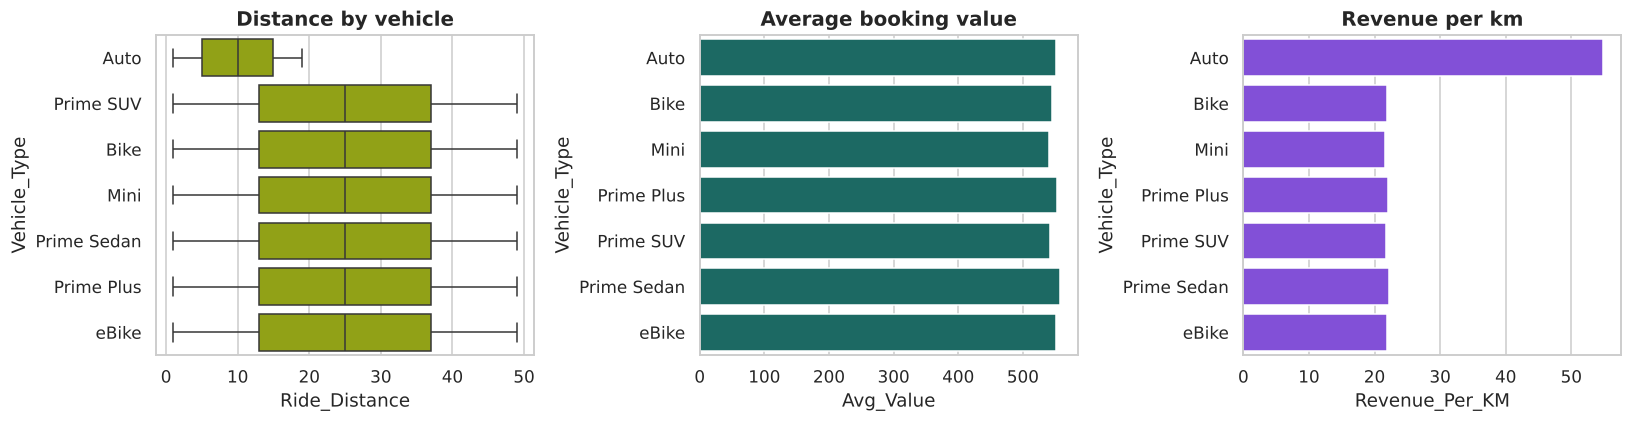

In [19]:
# Charts for vehicle types
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
order = vehicle.sort_values("Avg_Distance").index
sns.boxplot(data=ok, x="Ride_Distance", y="Vehicle_Type", order=order, ax=ax[0], color="#A3B800")
ax[0].set_title("Distance by vehicle")
sns.barplot(x=vehicle["Avg_Value"], y=vehicle.index, ax=ax[1], color="#0F766E")
ax[1].set_title("Average booking value")
sns.barplot(x=vehicle["Revenue_Per_KM"], y=vehicle.index, ax=ax[2], color="#7C3AED")
ax[2].set_title("Revenue per km")
plt.tight_layout()

**Observation**
- Auto rides are short: about 10 km on average and never above 19 km. All other vehicles average about 25 km.
- But the average booking value is almost the same for every vehicle (about Rs 541 to 557), even for Auto. So Auto earns around Rs 55 per km while others earn about Rs 22 per km. This is another sign that price does not follow distance.
- Ratings are the same for all vehicle types (about 4.0).

### 7.3 Categories against categories (vehicle type and booking status)
**Question:** Does the chance of a ride failing depend on the vehicle type? I use the Chi square test. If the p value is above 0.05, there is no real difference.

In [20]:
# Status share inside each vehicle type
table = pd.crosstab(df["Vehicle_Type"], df["Booking_Status"], normalize="index") * 100
display_table = table.round(2)
chi, p, dof, expected = stats.chi2_contingency(pd.crosstab(df["Vehicle_Type"], df["Booking_Status"]))
print("Chi square p value:", round(p, 3))
display_table

Chi square p value: 0.354

Booking_Status,Canceled by Customer,Canceled by Driver,Driver Not Found,Success
Vehicle_Type,,,,
Auto,10.19,18.13,9.56,62.13
Bike,10.48,17.45,9.77,62.30
Mini,10.34,17.76,9.81,62.09
Prime Plus,10.02,18.24,10.03,61.71
Prime SUV,10.22,18.07,10.32,61.39
Prime Sedan,9.88,17.42,9.66,63.04
eBike,10.21,18.18,9.65,61.96


**Observation:** The p value is above 0.05, so vehicle type does not change the chance of failure. All vehicle types succeed about 62% of the time.

## 8. Time analysis: is there a peak hour?

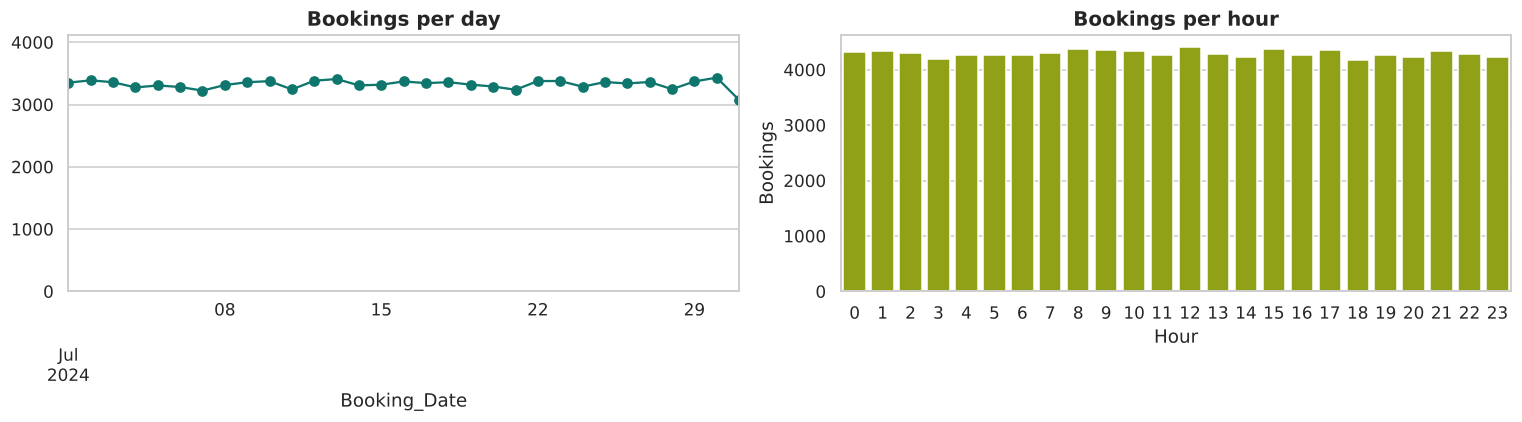

In [21]:
# Volume by day and by hour
daily = df.groupby("Booking_Date").size()
hourly = df.groupby("Hour").agg(Bookings=("Is_Success", "size"), Success_Rate=("Is_Success", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
daily.plot(ax=ax[0], color="#0F766E", marker="o")
ax[0].set_title("Bookings per day")
ax[0].set_ylim(0, daily.max() * 1.2)
sns.barplot(x=hourly.index, y=hourly["Bookings"], ax=ax[1], color="#A3B800")
ax[1].set_title("Bookings per hour")
plt.tight_layout()

In [22]:
# How different is the busiest hour from the quietest hour
print("Busiest hour:", hourly["Bookings"].idxmax(), "with", hourly["Bookings"].max(), "bookings")
print("Quietest hour:", hourly["Bookings"].idxmin(), "with", hourly["Bookings"].min(), "bookings")
print("Gap:", round((hourly["Bookings"].max() / hourly["Bookings"].min() - 1) * 100, 1), "percent")
print("Success rate range:", round(hourly["Success_Rate"].min() * 100, 1), "to", round(hourly["Success_Rate"].max() * 100, 1))

Busiest hour: 12 with 4408 bookings
Quietest hour: 18 with 4176 bookings
Gap: 5.6 percent
Success rate range: 60.4 to 63.6

**Observation:** Bookings stay near 4,300 every hour and the busiest hour is only about 5.6% above the quietest. There is no rush hour in this data.

In [23]:
# Weekday totals against weekday averages
days_seen = df.groupby("Day_Name")["Booking_Date"].nunique()
week = pd.DataFrame({"Total bookings": df.groupby("Day_Name").size(), "Days in July": days_seen})
week["Average per day"] = week["Total bookings"] / week["Days in July"]
week = week.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
week

,Total bookings,Days in July,Average per day
Day_Name,,,
Monday,16729,5,"3,345.80"
Tuesday,16926,5,"3,385.20"
Wednesday,16434,5,"3,286.80"
Thursday,13236,4,"3,309.00"
Friday,13345,4,"3,336.25"
Saturday,13341,4,"3,335.25"
Sunday,13013,4,"3,253.25"


**Observation:** Monday, Tuesday and Wednesday look busier in the totals only because July 2024 had five of each. After dividing by the number of days, every weekday has about 3,300 bookings. So averages should be compared, not totals.

In [24]:
# Is success rate different across hours or areas
p_hour = stats.chi2_contingency(pd.crosstab(df["Hour"], df["Booking_Status"]))[1]
p_area = stats.chi2_contingency(pd.crosstab(df["Pickup_Location"], df["Booking_Status"]))[1]
print("Hour against status, p value:", round(p_hour, 3))
print("Pickup area against status, p value:", round(p_area, 3))

Hour against status, p value: 0.198
Pickup area against status, p value: 0.09

**Observation:** Both p values are above 0.05. Success does not depend on the hour or the area. The failure problem is everywhere, so it is a company wide process issue and not a local one.

## 9. Why do rides fail?

,Customer reasons %,Driver reasons %
Canceled_Rides_by_Customer,,
AC is Not working,14.90,NaN
Change of plans,19.80,NaN
Customer related issue,NaN,29.40
Customer was coughing/sick,NaN,19.80
Driver asked to cancel,25.40,NaN
Driver is not moving towards pickup location,30.20,NaN
More than permitted people in there,NaN,15.30
Personal & Car related issue,NaN,35.50
Wrong Address,9.60,NaN


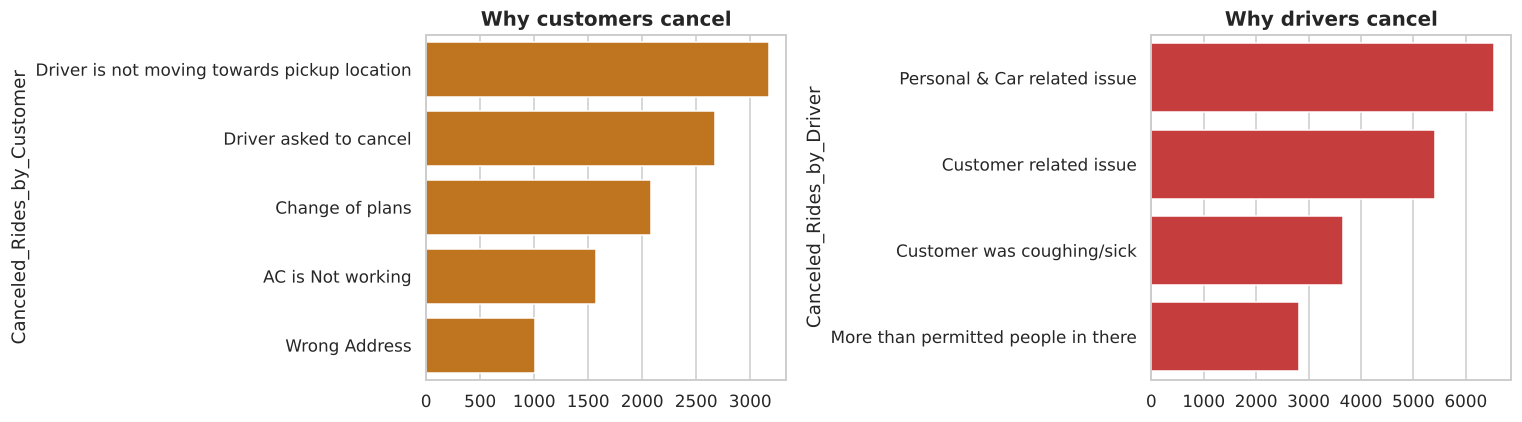

In [25]:
# Cancel reasons
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cust = df.loc[df["Booking_Status"] == "Canceled by Customer", "Canceled_Rides_by_Customer"].value_counts()
driver = df.loc[df["Booking_Status"] == "Canceled by Driver", "Canceled_Rides_by_Driver"].value_counts()
sns.barplot(x=cust.values, y=cust.index, ax=ax[0], color="#D97706")
ax[0].set_title("Why customers cancel")
sns.barplot(x=driver.values, y=driver.index, ax=ax[1], color="#DC2626")
ax[1].set_title("Why drivers cancel")
plt.tight_layout()
(cust / cust.sum() * 100).round(1).to_frame("Customer reasons %").join((driver / driver.sum() * 100).round(1).to_frame("Driver reasons %"), how="outer")

In [26]:
# Money lost because of failed bookings
lost = df[~df["Is_Success"]].groupby("Booking_Status")["Booking_Value"].agg(["count", "sum"])
lost.columns = ["Bookings", "Booking value lost"]
lost["Share of all bookings %"] = lost["Bookings"] / len(df) * 100
print("Total booking value lost:", f"Rs {lost['Booking value lost'].sum():,.0f}")
print("Revenue earned from completed rides:", f"Rs {ok['Booking_Value'].sum():,.0f}")
lost

Total booking value lost: Rs 21,454,147
Revenue earned from completed rides: Rs 35,080,467

,Bookings,Booking value lost,Share of all bookings %
Booking_Status,,,
Canceled by Customer,10499,5770901,10.19
Canceled by Driver,18434,10183427,17.89
Driver Not Found,10124,5499819,9.83


**Observation**
- Drivers cancel more than customers: 17.9% of bookings against 10.2%. That is 1.8 times higher.
- The top driver reason is personal or car related issue (35.5%), then customer related issue (29.4%).
- About 70% of customer cancels are caused by the service itself: the driver was not moving to the pickup point (30.2%), the driver asked to cancel (25.4%) or the AC was not working (14.9%). Only change of plans and wrong address are really the customer's reason.
- Failed bookings carry about Rs 2.15 Cr of booking value, against about Rs 3.51 Cr earned. In other words, for every rupee earned, about 61 paise were lost.
- Driver Not Found is 9.8% and equal everywhere, which is a general shortage of drivers.

## 10. Incomplete rides

In [27]:
# Incomplete rides inside successful rides
inc = ok[ok["Is_Incomplete"]]
print("Incomplete rides:", len(inc), "which is", round(len(inc) / len(ok) * 100, 1), "percent of completed rides")
print("Booking value at risk:", f"Rs {inc['Booking_Value'].sum():,.0f}")
inc["Incomplete_Rides_Reason"].value_counts().to_frame("Rides")

Incomplete rides: 3926 which is 6.1 percent of completed rides
Booking value at risk: Rs 2,250,482

,Rides
Incomplete_Rides_Reason,
Customer Demand,1601
Vehicle Breakdown,1591
Other Issue,734


**Observation:** 3,926 rides are marked Success and also Incomplete, worth about Rs 22.5 lakh. Vehicle breakdown (40.5%) is a fleet quality problem Ola can reduce. A careful report should show revenue with and without these rides.

## 11. Customers and locations

In [28]:
# How many times did each customer book
per_customer = df.groupby("Customer_ID").size()
freq = per_customer.value_counts().sort_index().to_frame("Customers")
freq["Share %"] = freq["Customers"] / freq["Customers"].sum() * 100
freq

,Customers,Share %
1,86590,91.59
2,7456,7.89
3,471,0.50
4,26,0.03
5,1,0.00


In [29]:
# Top customers by total value of completed rides
top = ok.groupby("Customer_ID").agg(Total_Value=("Booking_Value", "sum"), Rides=("Booking_ID", "size"))
top.sort_values("Total_Value", ascending=False).head(5)

,Total_Value,Rides
Customer_ID,,
CID836942,6019,4
CID868113,5986,2
CID695232,5962,2
CID176493,5944,2
CID902403,5938,2


**Observation:** 91.6% of customers booked only once and nobody booked more than five times. The top five customers by value mostly made only two rides, so they are not frequent riders. Customer retention is the open opportunity.

## 12. Same pickup and drop

In [30]:
# Bookings that start and end in the same area
same = df[df["Same_Pickup_Drop"]]
print("Bookings with same pickup and drop:", len(same))
print("Of them completed:", same["Is_Success"].sum(), "with average distance", round(same.loc[same["Is_Success"], "Ride_Distance"].mean(), 1), "km")

Bookings with same pickup and drop: 2121
Of them completed: 1306 with average distance 22.7 km

**Observation:** 2,121 bookings start and end in the same area, and 1,306 of them were completed with an average of about 22.7 km. A ride of 22 km cannot start and end at the same place, so these rows need to be checked.

## 13. Ratings

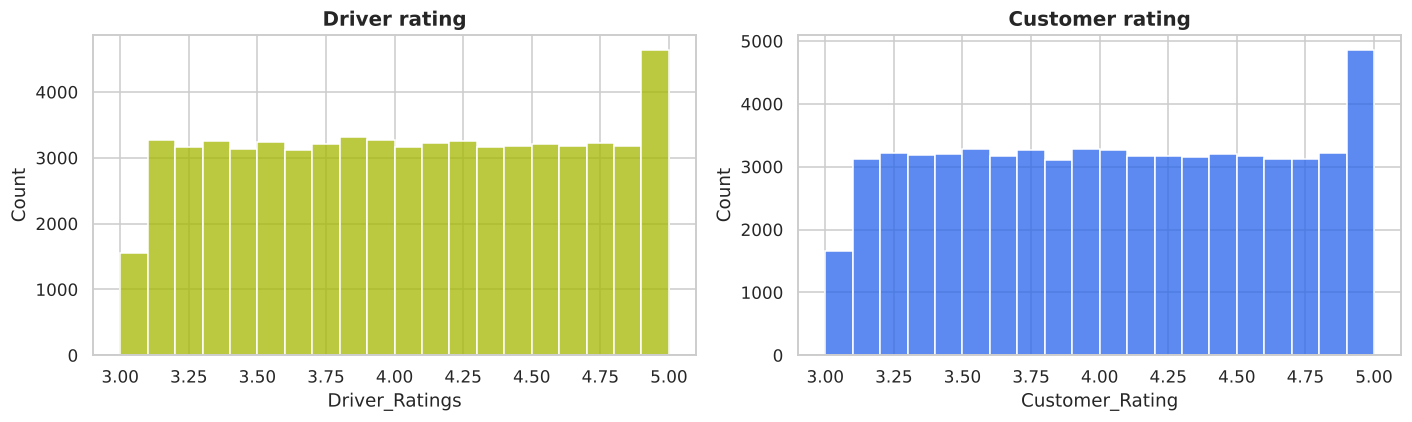

In [31]:
# Do ratings change with anything
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ok["Driver_Ratings"], bins=20, ax=ax[0], color="#A3B800")
ax[0].set_title("Driver rating")
sns.histplot(ok["Customer_Rating"], bins=20, ax=ax[1], color="#2563EB")
ax[1].set_title("Customer rating")
plt.tight_layout()

In [32]:
# Average rating by waiting time group and by payment method
wait_group = pd.qcut(ok["V_TAT"], 4, labels=["Fastest", "Fast", "Slow", "Slowest"])
print(ok.groupby(wait_group, observed=True)[["Driver_Ratings", "Customer_Rating"]].mean().round(3))
print(ok.groupby("Payment_Method")[["Driver_Ratings", "Customer_Rating"]].mean().round(3))

         Driver_Ratings  Customer_Rating
V_TAT                                   
Fastest            4.00             4.00
Fast               4.00             3.99
Slow               4.00             4.00
Slowest            3.99             4.00
                Driver_Ratings  Customer_Rating
Payment_Method                                 
Cash                      4.00             4.00
Credit Card               3.99             3.99
Debit Card                4.02             3.99
UPI                       4.00             3.99

**Observation:** Ratings are about 4.0 for every group, whether the driver arrived fast or slow, and for every payment type. Ratings are almost evenly spread from 3.0 to 5.0 with a floor at 3.0. So ratings cannot be used to find bad rides in this data.

## 14. Feature engineering
**What I do:** I created new columns to make the analysis easier. They are all created in `src/features.py`.

In [33]:
# New columns we created
new_columns = ["Booking_Date", "Hour", "Day_Name", "Is_Weekend", "Time_Slot", "Is_Success", "Is_Cancelled",
               "Is_Incomplete", "Failure_Owner", "Fare_Per_KM", "Same_Pickup_Drop", "Distance_Band", "Value_Band"]
df[new_columns].head(5)

,Booking_Date,Hour,Day_Name,Is_Weekend,Time_Slot,Is_Success,Is_Cancelled,Is_Incomplete,Failure_Owner,Fare_Per_KM,Same_Pickup_Drop,Distance_Band,Value_Band
0,2024-07-01,0,Monday,False,Late Night,True,False,False,NaN,25.52,False,30 to 40 km,400 to 800
1,2024-07-01,0,Monday,False,Late Night,False,True,False,Driver,NaN,False,NaN,200 to 400
2,2024-07-01,0,Monday,False,Late Night,False,True,False,Driver,NaN,False,NaN,Above 1500
3,2024-07-01,0,Monday,False,Late Night,True,False,True,NaN,4.62,False,20 to 30 km,Up to 200
4,2024-07-01,0,Monday,False,Late Night,True,False,False,NaN,34.00,False,0 to 5 km,Up to 200


| New column | Meaning | Why it helps |
|---|---|---|
| Hour, Day_Name, Time_Slot | When the booking was made | Find time patterns |
| Is_Success, Is_Cancelled | Simple yes or no flags | Easy success rate maths |
| Failure_Owner | Customer, Driver or No Supply | Shows who causes the loss |
| Fare_Per_KM | Booking value divided by distance | Finds pricing problems |
| Same_Pickup_Drop | Pickup equals drop | Data quality check |
| Distance_Band, Value_Band | Groups of distance and price | Easy grouping in charts |

## 15. Final summary

### Main findings
1. Only 62.1% of bookings become rides. About Rs 2.15 Cr of booking value is lost against Rs 3.51 Cr earned.
2. Drivers cancel 1.8 times more than customers (17.9% against 10.2%). About 70% of customer cancels are caused by the service.
3. Price does not follow distance (correlation 0.00). Auto earns about 2.5 times more per km than other vehicles only because short rides cost the same.
4. No peak hour exists and failures are the same in every hour, area and vehicle type. The problem is company wide.
5. Cash is 54.9% of revenue. Card payments are under 5%.
6. 6.1% of completed rides are incomplete, with vehicle breakdown as the top reason.
7. 91.6% of customers booked only once. Customer retention is low.
8. Ratings are flat and cannot separate good rides from bad ones.

### Recommendations
| Priority | Action |
|---|---|
| High | Reduce driver cancels with a cancel score, small penalties and fast re assignment |
| High | Alert drivers who do not move to the pickup after accepting, and add a vehicle comfort check |
| High | Audit the pricing logic because price is not linked to distance |
| Medium | Widen driver search and add incentives to cut Driver Not Found |
| Medium | Give small UPI cashback to move cash riders to digital payment |
| Medium | Report revenue with and without incomplete rides and add vehicle health checks |
| Medium | Launch a second ride offer to improve repeat customers |
| Low | Test surge pricing with small experiments because this data shows no peak hour |

### Limitations of this data
- Only one month, so no trend or season can be measured.
- No driver id, so driver level checks are not possible.
- Units of V_TAT and C_TAT are not given.
- The patterns are very even, so the data may be sample data. The conclusions should be confirmed on live data.

### Other project files
SQL queries are in `sql/ola_queries.sql`, the interactive dashboard is in `app.py`, and the full written report is in `report/Ola_Ride_Insights_Report.pdf`.